In [1]:
import pandas as pd
df = pd.read_csv("data/diabetic_data.csv", na_values="?", keep_default_na=False)
print(df.shape)
print(df["readmitted"].value_counts(normalize=True))
print(df.isna().mean().sort_values(ascending=False).head(10))

(101766, 50)
readmitted
NO     0.539119
>30    0.349282
<30    0.111599
Name: proportion, dtype: float64
weight               0.968585
medical_specialty    0.490822
payer_code           0.395574
race                 0.022336
diag_3               0.013983
diag_2               0.003518
diag_1               0.000206
admission_type_id    0.000000
patient_nbr          0.000000
encounter_id         0.000000
dtype: float64


C:\Users\paddi\AppData\Local\Temp\ipykernel_10636\1536992607.py:2: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/diabetic_data.csv", na_values="?", keep_default_na=False)


In [2]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [4]:
#Counting unique amount of patients
print(len(df))                  # number of hospital stays
print(df["patient_nbr"].nunique())  # number of different patients

101766
71518


In [5]:
df["A1Cresult"].value_counts()

A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

In [6]:
#Seeing how often each age group is having readmissions >30 days
pd.crosstab(df["age"], df["readmitted"], normalize="index")

readmitted,<30,>30,NO
age,,,
[0-10),0.018634,0.161491,0.819876
[10-20),0.057887,0.324168,0.617945
[20-30),0.142426,0.307785,0.549789
[30-40),0.112318,0.314437,0.573245
[40-50),0.106040,0.338462,0.555498
[50-60),0.096662,0.342895,0.560443
[60-70),0.111284,0.351243,0.537473
[70-80),0.117731,0.363472,0.518797
[80-90),0.120835,0.361865,0.517300


In [7]:
#checking the highest rate readmissions for <30 days and ranking them highest to lowest
rates = pd.crosstab(df["age"], df["readmitted"], normalize="index")["<30"]
rates.sort_values(ascending=False)

age
[20-30)     0.142426
[80-90)     0.120835
[70-80)     0.117731
[30-40)     0.112318
[60-70)     0.111284
[90-100)    0.110992
[40-50)     0.106040
[50-60)     0.096662
[10-20)     0.057887
[0-10)      0.018634
Name: <30, dtype: float64

In [8]:
#Checking how many patients are in each group
df["age"].value_counts().sort_index()

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

<Axes: title={'center': '30-day readmission rate by age'}, xlabel='age'>

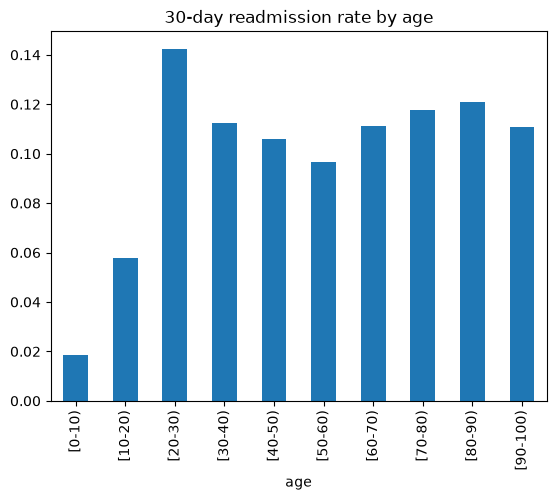

In [9]:
#First visual representation. Shows age of patients on the x-axis and 30 day readmission rate percentage on the y-axis
rates.plot(kind="bar", title="30-day readmission rate by age")

After an initial look at the data, it seems that the highest rated group for <30 day readmissions seems to be the 20-30 year olds. Maybe young adults are having a harder time managing their type 1 diabetes, however this data cannot provide useful insight or justifiable answer yet.